# 05 · The PyTorch extension: does the *meaning* of a description help?

**DSCI 510 project: Anticipating Attacks on Software Flaws**

`03_model.ipynb` found that the words of a description add signal beyond the structured fields
(publisher, weakness type, CVSS vector): +5.5 points of coverage at 10% effort on 2023, with an interval
above zero, so its go/no-go rule (Step 20) said **go**. Word counts (TF-IDF) only see words, though:
"execute arbitrary code" and "run commands" share none. This notebook asks the next question:

> Does a model that reads the **meaning** of each description, through a pretrained sentence-embedding
> model, rank new CVEs better than the word-count model of `03_model.ipynb`?

**How, in one paragraph.** A pretrained, frozen language model (`all-MiniLM-L6-v2`, published in 2021)
turns each cleaned description into 384 numbers that place descriptions with similar meaning close
together. A small neural network, written in PyTorch, reads those numbers together with the same
structured fields as `03_model.ipynb` and gives each CVE a risk score. Everything else is unchanged:
the same periods, the same measure (coverage at 5%, 10% and 26% effort), the same tie rule and paired
bootstrap, the same rule about the test year.

| Stage | What happens |
|:--|:--|
| A · Setup | Installation, settings, records, and the evaluation tools of `03_model.ipynb`, tested |
| B · Data | The analysis table, the permitted inputs, publisher names, the cleaned descriptions and the structured fields, all as in 03 |
| C · Sentence embeddings | Each cleaned description encoded once by the frozen model, cached and checked |
| D · The network | Inputs, the network, training with early stopping, and self-tests |
| E · Training and choosing on 2023 | 60 fits (3 feature sets × 4 settings × 5 seeds), the choice, and the comparison with 03 |
| F · The test year | The choice frozen; 2024 scored once (test-year copy only), against 03's model and EPSS |
| G · Summary | Findings, checks and files |

**Inputs:** the analysis table and its column dictionary, the acquisition log, the publisher names, and
from 03: `results/q2_selection.json` and `data/processed/model_scores_validate.parquet` (plus, in the
test-year copy, `model_scores_test.parquet` and notebook 01's `epss_benchmark.parquet`).

**Outputs:** `results/q5_*.csv` and `q5_*.json`, `figures/q5_*.png`, the cached embeddings in
`data/processed/embeddings/`, the scores in `data/processed/nn_scores_*.parquet`, and the run log
`logs/nn_log.json` (`nn_log_test.json` in the test-year copy).

**Runtime:** the first run installs PyTorch and sentence-transformers if missing (a few minutes),
downloads the language model once (about 90 MB, from Hugging Face), and encodes about 57,000
descriptions (a few minutes on a laptop; cached afterwards). Training the 60 networks takes roughly
10–20 minutes on a laptop processor; no graphics card is needed.

**Two copies, as in 03.** `05_pytorch_extension.ipynb` runs with the test year **sealed**
(`EVALUATE_TEST = False`): every choice is made on 2023, and no 2024 label is read.
`05_pytorch_extension_test.ipynb` is the same notebook with `EVALUATE_TEST = True`: it repeats every
choice (identically), freezes them with a fingerprint, logs the opening in
`logs/test_openings_nn.json`, and scores 2024 once. Run it on the same computer, after the sealed copy.

---

## Stage A · Setup

### Step 1 · Installing PyTorch and the sentence-embedding library

**What we are doing:** installing `torch` (PyTorch) and `sentence-transformers` if they are missing.
`03_model.ipynb` (Step 20, check F1) confirmed that PyTorch publishes a build for this Python version.

**Why:** PyTorch trains the network; `sentence-transformers` loads the pretrained language model and
encodes the descriptions. After an installation, restart the kernel once and run all cells again.

In [1]:
%pip install --quiet torch sentence-transformers scikit-learn pyarrow

Note: you may need to restart the kernel to use updated packages.


**The imports:** the next cell loads everything and records the versions. PyTorch is told to use
deterministic algorithms and a single processor thread, so that the same seed gives exactly the same
network on every run.

In [2]:
import copy, hashlib, json, re, sys, time
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import torch
from torch import nn
import sentence_transformers

torch.use_deterministic_algorithms(True)
torch.set_num_threads(1)                  # one thread: identical results on every run
VERSIONS = {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
            "scikit-learn": sklearn.__version__, "torch": torch.__version__,
            "sentence-transformers": sentence_transformers.__version__}
print(" | ".join(f"{name} {version}" for name, version in VERSIONS.items()))

python 3.14.6 | pandas 3.0.3 | numpy 2.4.6 | scikit-learn 1.9.0 | torch 2.15.0+cpu | sentence-transformers 6.3.0


**Reading the result:** one line of versions, including PyTorch's. A `ModuleNotFoundError` means the
installation in Step 1 needs a kernel restart.

### Step 2 · Settings, fixed before any result

**What we are doing:** the folders, the evaluation settings (the same as in 03), the language model,
and the network's settings and small grid.

**Why:** as in 03, every choice is written down before any result is seen. The grid is deliberately
small (2 dropout rates × 2 weight-decay strengths): with 145 exploited CVEs in 2023, many settings
would only fit the noise of that year. Each setting is trained with **5 seeds** (different random
starting points), and the 5 networks' scores are averaged, which makes the result far less dependent
on luck.

| Setting | Value | Meaning |
|:--|:--|:--|
| `MODEL_NAME`, `MODEL_REVISION` | all-MiniLM-L6-v2, a fixed revision | the pretrained language model, pinned so it never changes |
| `HIDDEN` | 128, then 32 | the sizes of the network's two hidden layers |
| `LEARNING_RATE`, `BATCH_SIZE` | 0.001, 256 | how big each training step is; how many CVEs per step |
| `MAX_EPOCHS`, `PATIENCE` | 30, 5 | at most 30 passes over the training CVEs; stop after 5 passes without improvement on 2023 |
| `NET_GRID` | dropout 0.2 or 0.5; weight decay 0.0001 or 0.001 | two ways of holding the network back from memorising |
| `SEEDS` | 510–514 | five random starting points per setting |

In [3]:
# ---- Folders ----
PROCESSED, RAW = Path("data") / "processed", Path("data") / "raw"
RESULTS, FIGURES, LOGS = Path("results"), Path("figures"), Path("logs")
EMBED_DIR = PROCESSED / "embeddings"                      # one file per period, reused by later runs
for folder in (RESULTS, FIGURES, LOGS, EMBED_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# ---- Periods, label and the test-year switch (as in 03) ----
PERIODS = ["train", "validate", "test"]
PERIOD_NAMES = {"train": "Nov 2021–2022", "validate": "2023", "test": "2024"}
LABEL = "label_365"
EVALUATE_TEST = False                     # True only in the test-year copy

# ---- Evaluation (as in 03) ----
SEED, N_BOOT = 510, 1000
EFFORTS = [0.05, 0.10, 0.26]
PRIMARY_EFFORT = 0.10
MIN_CATEGORY, MAX_CATEGORIES = 20, 250    # the structured encoder of 03, unchanged

# ---- The frozen language model ----
MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"   # 384 numbers per description; published in 2021
MODEL_REVISION = "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"   # a fixed snapshot of the model's files
EMBED_BATCH, EMBED_CHUNK = 64, 4000       # descriptions per batch; per progress line

# ---- The network ----
HIDDEN = (128, 32)
LEARNING_RATE, BATCH_SIZE = 1e-3, 256
MAX_EPOCHS, PATIENCE = 30, 5
NET_GRID = [{"dropout": d, "weight_decay": w} for d in (0.2, 0.5) for w in (1e-4, 1e-3)]
SEEDS = [510, 511, 512, 513, 514]
FEATURE_SETS = {"structured": ["structured"], "text": ["text"], "structured + text": ["structured", "text"]}

# ---- 03's choices, for the comparison ----
SELECTION_03 = json.loads((RESULTS / "q2_selection.json").read_text(encoding="utf-8"))
FINAL_03 = SELECTION_03["final_model"]
print(f"test year sealed: {not EVALUATE_TEST} | {len(FEATURE_SETS)} feature sets x {len(NET_GRID)} settings x "
      f"{len(SEEDS)} seeds = {len(FEATURE_SETS) * len(NET_GRID) * len(SEEDS)} networks | 03's final model: {FINAL_03}")

test year sealed: True | 3 feature sets x 4 settings x 5 seeds = 60 networks | 03's final model: LR · structured + text


**Reading the result:** the seal, the number of networks to train (60), and 03's final model, the
benchmark on 2023.

### Step 3 · Recording checks and saving outputs

**What we are doing:** the record-keeping tools of `03_model.ipynb`, copied word for word, writing this
notebook's own run log (`nn_log.json`, or `nn_log_test.json` in the test-year copy).

In [4]:
def now_iso():
    "Current local time with its UTC offset."
    return dt.datetime.now().astimezone().isoformat(timespec="seconds")

def check(name, ok, **details):
    "Record one check and print its verdict. ok=True is PASS, False is FAIL, None is WARN."
    verdict = "WARN" if ok is None else ("PASS" if ok else "FAIL")
    RUN["checks"][name] = {"verdict": verdict, **details}
    print(f"{verdict}  {name}" + (f"  |  {details}" if details else ""))

def show_conditions(conditions):
    "Print a {description: passed} checklist; return the descriptions that failed."
    for description, passed in conditions.items():
        print(f"  {'ok ' if passed else 'NO '} {description}")
    return [description for description, passed in conditions.items() if not passed]

def save_table(df, name, index=True):
    "Save a result table as results/<name>.csv and remember it for the summary."
    path = RESULTS / f"{name}.csv"
    df.to_csv(path, index=index)
    RUN["files"].append(str(path))
    return path

def save_json(obj, path):
    "Write obj as indented JSON and remember the file."
    Path(path).write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")
    RUN["files"].append(str(path))

def stop(message):
    "Save the log so far, then halt: used only when going on would train a misleading model."
    RUN["stopped"] = message
    LOG_FILE.write_text(json.dumps(RUN, indent=2, default=str), encoding="utf-8")
    raise RuntimeError(message)

RUN = {"started": now_iso(), "checks": {}, "files": [], "versions": VERSIONS, "evaluate_test": EVALUATE_TEST}
LOG_FILE = LOGS / ("nn_log_test.json" if EVALUATE_TEST else "nn_log.json")
SUMMARY_FILE = RESULTS / ("q5_summary_test.json" if EVALUATE_TEST else "q5_summary.json")

**The chart style:** the same as in the other notebooks; the neural network is drawn in violet.

In [5]:
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#898781"           # primary, secondary, muted text
SET_COLORS = {"structured": "#2a78d6", "text": "#eb6834", "structured + text": "#1baf7a"}
BASELINE_GREY = "#898781"

def pick_font(candidates=("Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans")):
    "The first installed font from the list (checked quietly, so matplotlib prints no warnings)."
    for name in candidates:
        try:
            font_manager.findfont(name, fallback_to_default=False)
            return name
        except ValueError:
            continue
    return "sans-serif"

plt.rcParams.update({
    "font.family": pick_font(), "font.size": 9.5,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK_2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_3, "ytick.color": INK_3, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False, "text.color": INK,
})

def save_figure(fig, name, note=None):
    "Add an optional note just below everything drawn, save figures/<name>.png, and show the figure."
    if note:
        fig.canvas.draw()                                         # lay out first, so the bounding box is final
        box = fig.get_tightbbox(fig.canvas.get_renderer())       # in inches
        fig.text(box.x0 / fig.get_figwidth(), (box.y0 - 0.08) / fig.get_figheight(), note,
                 ha="left", va="top", fontsize=8, color=INK_3)
    path = FIGURES / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    RUN["files"].append(str(path))
    plt.show()
    plt.close(fig)

print("chart style ready | font:", pick_font())
NN_COLOR = "#7b61c9"

chart style ready | font: Segoe UI


### Step 4 · The evaluation tools

**What we are doing:** the measure of `03_model.ipynb`, copied word for word: coverage at a given
effort with tied scores split evenly, and the paired bootstrap for intervals and differences. The next
three cells are the measure, its uncertainty, and the six self-tests with known answers.

In [6]:
class Ranking:
    "CVEs sorted by score, highest first, with equal scores grouped. Computed once per model, reused."
    def __init__(self, score):
        score = np.asarray(score, dtype=float)
        if score.size == 0 or not np.isfinite(score).all():
            raise ValueError("scores must be finite and not empty")
        self.order = np.argsort(-score, kind="stable")
        ranked = score[self.order]
        self.group = np.cumsum(np.r_[True, ranked[1:] != ranked[:-1]]) - 1   # tie-group number, in rank order
        self.n_groups, self.n = int(self.group[-1]) + 1, score.size

def coverage(ranking, y, efforts, weights=None):
    "Expected (coverage, precision) when the top `effort` share is handled, ties split evenly."
    y = np.asarray(y, dtype=float)[ranking.order]
    w = np.ones(ranking.n) if weights is None else np.asarray(weights, dtype=float)[ranking.order]
    size = np.bincount(ranking.group, weights=w, minlength=ranking.n_groups)       # CVEs per tie group
    hits = np.bincount(ranking.group, weights=w * y, minlength=ranking.n_groups)   # exploited per group
    cum_size, cum_hits = np.cumsum(size), np.cumsum(hits)
    k = np.asarray(efforts, dtype=float) * cum_size[-1]                           # CVEs handled
    g = np.minimum(np.searchsorted(cum_size, k, side="left"), ranking.n_groups - 1)  # group holding the cut
    taken = np.divide(k - (cum_size[g] - size[g]), size[g], out=np.zeros_like(k), where=size[g] > 0)
    found = cum_hits[g] - hits[g] + hits[g] * np.clip(taken, 0, 1)
    total = cum_hits[-1]
    cov = found / total if total > 0 else np.full_like(k, np.nan)
    return cov, np.divide(found, k, out=np.full_like(k, np.nan), where=k > 0)

The cell above defines the measure. The next one adds its uncertainty.

In [7]:
def bootstrap_coverage(y, rankings, efforts, n_boot=N_BOOT, seed=SEED):
    "Coverage of every ranking on the same resamples of CVEs: an array (n_boot, rankings, efforts)."
    rng, n = np.random.default_rng(seed), len(y)
    out = np.empty((n_boot, len(rankings), len(efforts)))
    for b in range(n_boot):
        weights = np.bincount(rng.integers(0, n, n), minlength=n)    # how often each CVE was drawn
        for j, ranking in enumerate(rankings.values()):
            out[b, j] = coverage(ranking, y, efforts, weights)[0]
    return out

def tag(effort):
    "Column suffix for an effort: 0.10 -> '10'."
    return f"{round(effort * 100)}"

def evaluation_table(y, scores, efforts=EFFORTS, n_boot=N_BOOT):
    "Coverage (with 95% interval) and precision at each effort, and average precision, per model."
    rankings = {name: Ranking(s) for name, s in scores.items()}
    boot = bootstrap_coverage(y, rankings, efforts, n_boot)
    rows = []
    for j, (name, ranking) in enumerate(rankings.items()):
        cov, prec = coverage(ranking, y, efforts)
        row = {"model": name}
        for i, e in enumerate(efforts):
            low, high = np.percentile(boot[:, j, i], [2.5, 97.5])
            row.update({f"coverage_{tag(e)}": cov[i], f"coverage_{tag(e)}_low": low,
                        f"coverage_{tag(e)}_high": high, f"precision_{tag(e)}": prec[i]})
        row["average_precision"] = average_precision_score(y, scores[name])
        rows.append(row)
    return pd.DataFrame(rows).set_index("model"), boot

def difference(table, boot, a, b, effort):
    "Coverage of model b minus model a at one effort, with its paired 95% interval."
    names, i = list(table.index), EFFORTS.index(effort)
    diffs = boot[:, names.index(b), i] - boot[:, names.index(a), i]
    estimate = table.loc[b, f"coverage_{tag(effort)}"] - table.loc[a, f"coverage_{tag(effort)}"]
    return (estimate, *np.percentile(diffs, [2.5, 97.5]))

**Testing the tools:** the six tests of `03_model.ipynb`.

In [8]:
rng = np.random.default_rng(1)
y10 = np.array([1, 1, 0, 0, 0, 0, 0, 0, 0, 0])
perfect = coverage(Ranking(np.arange(10, 0, -1)), y10, [0.2])
tied = coverage(Ranking(np.zeros(10)), y10, [0.3])

scores_t = np.round(rng.uniform(0, 1, 200), 1)              # 11 distinct values: many ties
y_t = (rng.random(200) < 0.2).astype(int)
formula = coverage(Ranking(scores_t), y_t, [0.2])[0][0]
brute = np.mean([y_t[np.lexsort((rng.random(200), -scores_t))][:40].sum() / y_t.sum() for _ in range(3000)])

doubled = coverage(Ranking(np.r_[scores_t, scores_t]), np.r_[y_t, y_t], EFFORTS)[0]
weighted = coverage(Ranking(scores_t), y_t, EFFORTS, weights=np.full(200, 2))[0]
same = bootstrap_coverage(y_t, {"a": Ranking(scores_t), "b": Ranking(scores_t)}, EFFORTS, n_boot=50)
again = bootstrap_coverage(y_t, {"a": Ranking(scores_t)}, EFFORTS, n_boot=50)

failed = show_conditions({
    "perfect ranking: 100% coverage and precision at 20% effort": np.allclose(perfect, [[1.0], [1.0]]),
    "all scores tied: coverage 30% at 30% effort": np.isclose(tied[0][0], 0.3),
    "ties: formula agrees with 3,000 random orders (within 0.01)": abs(formula - brute) < 0.01,
    "a weight of 2 equals listing every CVE twice": np.allclose(doubled, weighted),
    "identical rankings differ by exactly zero": np.array_equal(same[:, 0], same[:, 1]),
    "the same seed gives the same resamples": np.array_equal(same[:, 0], again[:, 0]),
})
print(f"tied example: formula {formula:.4f}, average of random orders {brute:.4f}")
check("A1-evaluation-selftest", not failed, tests=6, failed=failed)

  ok  perfect ranking: 100% coverage and precision at 20% effort
  ok  all scores tied: coverage 30% at 30% effort
  ok  ties: formula agrees with 3,000 random orders (within 0.01)
  ok  a weight of 2 equals listing every CVE twice
  ok  identical rankings differ by exactly zero
  ok  the same seed gives the same resamples
tied example: formula 0.2157, average of random orders 0.2156
PASS  A1-evaluation-selftest  |  {'tests': 6, 'failed': []}


**Reading the result:** six `ok` lines and `PASS`.

---

## Stage B · The data, exactly as in 03

### Step 5 · Load the analysis table and check it

**What we are doing:** the loading and checks of `03_model.ipynb` (Steps 5–6), copied word for word:
the table must match the acquisition run, and only permitted columns may reach a model. The 2024 rows
are not loaded here.

In [9]:
def load_acquisition_reference(path=LOGS / "acquisition_log.json"):
    "Rows and exploited counts per split recorded by 01_acquire_data.ipynb, or None if unavailable."
    try:
        log = json.loads(path.read_text(encoding="utf-8"))
        d2 = log["checks"]["D2-analysis-table"]
        return {"rows": d2["rows"], "exploited": d2["exploited"]}
    except (FileNotFoundError, KeyError, json.JSONDecodeError) as exc:
        print(f"no usable acquisition log ({exc!r}): the comparison below will be WARN")
        return None

table = pd.read_parquet(PROCESSED / "analysis_table.parquet")
columns = pd.read_csv(PROCESSED / "analysis_table_columns.csv")
reference = load_acquisition_reference()

needed = {"cve_id", "published", "split", "cna", "description", "cvss_score", "cvss_vector", "cvss_version",
          "cwe_primary", LABEL, "kev_before_publication", "kev_date_added"}
exploited = table.groupby("split")[LABEL].sum().astype(int).to_dict()
failed = show_conditions({                                   # integrity: must hold in any case
    "every needed column is present": needed <= set(table.columns),
    "one row per CVE": not table["cve_id"].duplicated().any(),
    "the label has no missing values": int(table[LABEL].isna().sum()) == 0,
})
if reference:                                                # agreement with the acquisition run
    failed += show_conditions({
        "rows match the acquisition run": len(table) == reference["rows"],
        "exploited per split match the acquisition run": exploited == reference["exploited"],
    })
check("B1-table-loaded", False if failed else (True if reference else None), rows=len(table), failed=failed)

  ok  every needed column is present
  ok  one row per CVE
  ok  the label has no missing values
  ok  rows match the acquisition run
  ok  exploited per split match the acquisition run
PASS  B1-table-loaded  |  {'rows': 187219, 'failed': []}


**Reading the result:** five `ok` lines and `PASS`, as in 03.

**Only permitted inputs:** the same six feature columns as 03, checked against the column dictionary.
If one is not permitted, the run stops before any network is trained.

In [10]:
FEATURE_COLUMNS = ["cna", "description", "cvss_score", "cvss_vector", "cvss_version", "cwe_primary"]

permitted = set(columns.loc[columns["may_be_model_input"].astype(str).str.lower() == "true", "column"])
forbidden = set(columns.loc[columns["role"].isin(["label", "diagnostic", "split", "provenance"]), "column"])
failed = show_conditions({
    "every feature column is marked as a permitted input": set(FEATURE_COLUMNS) <= permitted,
    "no feature column is a label, KEV, split or NVD-added column":
        not (set(FEATURE_COLUMNS) & forbidden) and not any(c.startswith(("diag_", "kev_")) for c in FEATURE_COLUMNS),
})
check("B2-inputs-permitted", not failed, features=FEATURE_COLUMNS, failed=failed)
if failed:
    stop("a feature column is not a permitted input: no model is trained on it")

def period_frame(name):
    "One period's CVEs: id, feature columns, the label, and the before-publication flag (for evaluation only)."
    keep = ["cve_id"] + FEATURE_COLUMNS + [LABEL, "kev_before_publication"]
    return table.loc[table["split"] == name, keep].reset_index(drop=True)

frames = {p: period_frame(p) for p in ("train", "validate")}   # 2024 is not even loaded until Stage G
for p, f in frames.items():
    print(f"{PERIOD_NAMES[p]:>14}: {len(f):,} CVEs, {int(f[LABEL].sum())} exploited ({f[LABEL].mean():.2%})")

  ok  every feature column is marked as a permitted input
  ok  no feature column is a label, KEV, split or NVD-added column
PASS  B2-inputs-permitted  |  {'features': ['cna', 'description', 'cvss_score', 'cvss_vector', 'cvss_version', 'cwe_primary'], 'failed': []}
 Nov 2021–2022: 28,368 CVEs, 128 exploited (0.45%)
          2023: 28,816 CVEs, 145 exploited (0.50%)


**Reading the result:** `PASS`, then the two periods used for every choice.

### Step 6 · Publisher names

**What we are doing:** 03's Step 7, word for word: publisher names from the cached NVD list.

In [11]:
SOURCES_CACHE = RAW / "nvd_sources.json"
try:
    _sources = json.loads(SOURCES_CACHE.read_text(encoding="utf-8"))
except (FileNotFoundError, json.JSONDecodeError):
    _sources = []
PUBLISHER_NAMES = {identifier: s["name"].strip() for s in _sources if s.get("name")
                   for identifier in s.get("sourceIdentifiers", [])}
WORDPRESS = re.compile(r"wordfence|patchstack|wpscan", re.IGNORECASE)

def publisher_of(df):
    "The publisher's name where known, otherwise its identifier."
    return df["cna"].map(PUBLISHER_NAMES).fillna(df["cna"])

def is_wordpress(df):
    "True for CVEs issued by the WordPress plug-in publishers."
    return publisher_of(df).str.contains(WORDPRESS) | df["cna"].str.contains(WORDPRESS)

named = frames["train"]["cna"].isin(list(PUBLISHER_NAMES)).mean()
print(f"publisher names: {len(PUBLISHER_NAMES):,} identifiers from the cache; {named:.1%} of training CVEs named")
for p, f in frames.items():
    print(f"{PERIOD_NAMES[p]:>14}: {publisher_of(f).nunique()} publishers; WordPress plug-in publishers issue "
          f"{is_wordpress(f).mean():.1%} of CVEs and {int(f.loc[is_wordpress(f), LABEL].sum())} exploited ones")

publisher names: 831 identifiers from the cache; 100.0% of training CVEs named
 Nov 2021–2022: 205 publishers; WordPress plug-in publishers issue 6.7% of CVEs and 0 exploited ones
          2023: 256 publishers; WordPress plug-in publishers issue 13.7% of CVEs and 0 exploited ones


### Step 7 · The cleaned descriptions

**What we are doing:** 03's Steps 8–9, word for word: the phrases that state exploitation, and the
cleaning that drops every sentence containing one. The language model reads the **cleaned** text only,
so it can never read an answer edited into a description after the fact (03's audit found such edits).

In [12]:
EXPLOITATION_PHRASES = [
    r"\bexploited in the wild\b", r"\bin the wild\b", r"\bactively exploited\b",
    r"\b(?:has|have|had|may have) been (?:actively )?exploited\b", r"\b(?:was|were) (?:actively )?exploited\b",
    r"\bis being (?:actively )?exploited\b", r"\btargeted exploitation\b",
    r"\bexploitation (?:has been |was )?(?:observed|detected|reported)\b",
    r"\bknown exploited vulnerabilit", r"\baware of (?:a |an )?(?:report|reports|exploit)",
]

PHRASE = re.compile("|".join(EXPLOITATION_PHRASES), re.IGNORECASE)

def has_phrase(texts):
    "True where a text states that the flaw is or was exploited."
    return texts.fillna("").str.contains(PHRASE)

The cell above finds the phrases. The next one removes the sentences that contain them, with 03's
self-test.

In [13]:
SENTENCE_END = re.compile(r"(?<=[.!?])\s+")

def mask_exploitation(text):
    "The description without any sentence that says the flaw is or was exploited."
    if not isinstance(text, str):
        return ""
    if not PHRASE.search(text):
        return text                                    # untouched, spacing included
    return " ".join(s for s in SENTENCE_END.split(text) if not PHRASE.search(s))

examples = {
    "Use after free in WebKit. Apple is aware of a report that this issue may have been actively exploited.":
        "Use after free in WebKit.",
    "An attacker could exploit this flaw to run code. Versions before 2.1 are affected.":
        "An attacker could exploit this flaw to run code. Versions before 2.1 are affected.",
    "Fortinet is aware of an instance where this vulnerability was exploited in the wild.": "",
}
for f in frames.values():
    f["text"] = f["description"].map(mask_exploitation)                 # what the models read
failed = show_conditions({
    "a sentence stating exploitation is removed, the rest kept":
        all(mask_exploitation(a) == b for a, b in examples.items()),
    "'could exploit' (a possibility, not a fact) is kept": mask_exploitation("It could be exploited.") != "",
    "a missing description becomes empty text": mask_exploitation(None) == "",
    "no cleaned description still contains a phrase":
        not any(has_phrase(f["text"]).any() for f in frames.values()),
})
removed = sum(int((f["text"] != f["description"].fillna("")).sum()) for f in frames.values())
print(f"descriptions changed by the cleaning: {removed:,} of {sum(len(f) for f in frames.values()):,}")
check("C1-description-masking", not failed, changed=removed, failed=failed)

  ok  a sentence stating exploitation is removed, the rest kept
  ok  'could exploit' (a possibility, not a fact) is kept
  ok  a missing description becomes empty text
  ok  no cleaned description still contains a phrase
descriptions changed by the cleaning: 148 of 57,184
PASS  C1-description-masking  |  {'changed': 148, 'failed': []}


**Reading the result:** four `ok` lines and `PASS`; 148 descriptions changed, as in 03.

### Step 8 · The structured fields

**What we are doing:** 03's Steps 11–12, word for word: the parts of the CVSS vector, the structured
inputs, and the encoder that keeps publishers and weakness types with at least 20 CVEs in the fitting
data (rarer and unseen ones become "other").

**How the network uses them:** the encoder's 0/1 columns go straight into the network's first layer.
A first layer reading a 0/1 column per publisher is exactly a **learned embedding** of the publisher
(one set of weights per publisher), which is what the extension plan asked for.

In [14]:
COMPONENTS = ["AV", "AC", "PR", "UI", "S", "AT", "C", "I", "A"]
V4_NAMES = {"VC": "C", "VI": "I", "VA": "A"}                  # version 4's names for the impact metrics

def vector_components(vectors):
    "One column per CVSS 3.x/4.0 base component (codes such as N, L, H); 'missing' where absent."
    modern = vectors.where(vectors.str.startswith("CVSS:3", na=False) | vectors.str.startswith("CVSS:4", na=False))
    pairs = modern.str.findall(r"/([A-Z]+):([A-Z])")
    rows = [{V4_NAMES.get(k, k): v for k, v in p} if isinstance(p, list) else {} for p in pairs]
    parsed = pd.DataFrame(rows, index=vectors.index).reindex(columns=COMPONENTS)
    parsed["UI"] = parsed["UI"].replace({"P": "R", "A": "R"})   # passive or active: required either way
    return parsed.fillna("missing")

_parsed = vector_components(pd.Series(["CVSS:3.1/AV:N/AC:L/PR:N/UI:R/S:U/C:H/I:H/A:N",
                                       "CVSS:4.0/AV:L/AC:L/AT:P/PR:H/UI:A/VC:H/VI:L/VA:N/SC:N/SI:N/SA:N",
                                       "AV:N/AC:L/Au:N/C:P/I:P/A:P", None]))
failed = show_conditions({
    "a 3.1 vector: N, L, N, R, U, (no AT), H, H, N":
        _parsed.iloc[0].tolist() == ["N", "L", "N", "R", "U", "missing", "H", "H", "N"],
    "a 4.0 vector: VC/VI/VA become C/I/A, active interaction is 'R'":
        _parsed.iloc[1].tolist() == ["L", "L", "H", "R", "missing", "P", "H", "L", "N"],
    "a version 2 vector is left unparsed": (_parsed.iloc[2] == "missing").all(),
    "a missing vector gives 'missing' everywhere": (_parsed.iloc[3] == "missing").all(),
})
check("D0-cvss-parser-selftest", not failed, tests=4, failed=failed)

  ok  a 3.1 vector: N, L, N, R, U, (no AT), H, H, N
  ok  a 4.0 vector: VC/VI/VA become C/I/A, active interaction is 'R'
  ok  a version 2 vector is left unparsed
  ok  a missing vector gives 'missing' everywhere
PASS  D0-cvss-parser-selftest  |  {'tests': 4, 'failed': []}


The cell above splits the CVSS vector. The next two define the structured inputs and their encoder.

In [15]:
CATEGORICAL = ["publisher", "cwe", "cvss_version"] + COMPONENTS
NUMERIC = ["cvss_score", "log_description_len"]

def structured_inputs(df):
    "The structured inputs of each CVE, as readable columns (categories as text, two numbers)."
    raw = pd.DataFrame({"publisher": publisher_of(df), "cwe": df["cwe_primary"].fillna("missing"),
                        "cvss_version": df["cvss_version"].fillna("missing").astype(str)}, index=df.index)
    raw = raw.join(vector_components(df["cvss_vector"]))
    raw["cvss_score"] = df["cvss_score"].astype(float).fillna(0.0)
    raw["log_description_len"] = np.log1p(df["text"].str.len().astype(float))
    return raw

print(f"{len(CATEGORICAL)} categorical inputs: {CATEGORICAL}; numbers: {NUMERIC}")

12 categorical inputs: ['publisher', 'cwe', 'cvss_version', 'AV', 'AC', 'PR', 'UI', 'S', 'AT', 'C', 'I', 'A']; numbers: ['cvss_score', 'log_description_len']


**The encoder,** as in 03.

In [16]:
class StructuredEncoder:
    "Keeps the categories common in the fitting data (the rest become 'other'); encodes for both model families."
    def fit(self, raw):
        self.keep, self.n_fit = {}, len(raw)
        for col in CATEGORICAL:
            counts = raw[col].value_counts()
            common = counts[counts >= MIN_CATEGORY].index[:MAX_CATEGORIES - 1]
            self.keep[col] = sorted(set(common) | {"other"})
        lumped = self.lump(raw)
        self.onehot = OneHotEncoder(categories=[self.keep[c] for c in CATEGORICAL], handle_unknown="ignore",
                                    sparse_output=True).fit(lumped[CATEGORICAL])
        self.scaler = StandardScaler().fit(raw[NUMERIC])
        return self

    def lump(self, raw):
        "Categories not kept at fitting time (rare, or never seen) become 'other'."
        out = raw.copy()
        for col in CATEGORICAL:
            out[col] = out[col].where(out[col].isin(self.keep[col]), "other")
        return out

    def sparse(self, raw):
        "0/1 columns for each kept category, plus the standardised numbers (logistic regression)."
        lumped = self.lump(raw)
        return sp.hstack([self.onehot.transform(lumped[CATEGORICAL]),
                          sp.csr_matrix(self.scaler.transform(raw[NUMERIC]))]).tocsr()

    def dense(self, raw):
        "Category codes plus the raw numbers (gradient boosting)."
        lumped = self.lump(raw)
        codes = [pd.Categorical(lumped[c], categories=self.keep[c]).codes for c in CATEGORICAL]
        return np.column_stack(codes + [raw[c].to_numpy(float) for c in NUMERIC])

    def names(self):
        "Column names of the sparse form, in order (the one-hot columns follow self.keep)."
        return [f"{col}: {cat}" for col in CATEGORICAL for cat in self.keep[col]] + NUMERIC

---

## Stage C · Sentence embeddings

### Step 9 · Encoding the cleaned descriptions

**What we are doing:** loading the pretrained language model once, and turning every cleaned
description into 384 numbers (an **embedding**). Descriptions with similar meaning get similar numbers,
even when they share no words. The model is **frozen**: it is used as it was published, never trained
here.

**Why this model:** `all-MiniLM-L6-v2` is small (about 90 MB), runs on a laptop processor, and was first
published in August 2021, so it cannot have learned anything about 2024's CVEs. It is pinned to one
revision of its files, so a later update cannot change the results. It reads at most 256 word pieces;
longer descriptions are cut, and Step 10 counts how many.

**The cache:** each period's embeddings are saved in `data/processed/embeddings/<period>.npz`, together
with a fingerprint of the exact texts and the model's name and revision. A later run reuses the file
only if all three still match; otherwise it encodes again. Files are written to a temporary name and
then renamed, so an interrupted run never leaves half a file.

In [17]:
MODEL_TAG = f"{MODEL_NAME}@{MODEL_REVISION}"
_ENCODER = {}

def encoder():
    "The frozen sentence-embedding model, loaded once (downloaded on first use, then cached by Hugging Face)."
    if "model" not in _ENCODER:
        from sentence_transformers import SentenceTransformer
        try:
            _ENCODER["model"] = SentenceTransformer(MODEL_NAME, revision=MODEL_REVISION, device="cpu")
        except Exception as exc:                                      # no network, or Hugging Face unreachable
            raise RuntimeError(f"could not load {MODEL_NAME} at revision {MODEL_REVISION[:8]} from Hugging Face "
                               f"({type(exc).__name__}): check the internet connection and run this cell "
                               "again") from exc
    return _ENCODER["model"]

def text_fingerprint(texts):
    "SHA-256 of the exact texts, in order."
    return hashlib.sha256("\x1f".join(texts).encode("utf-8")).hexdigest()

def encode(texts):
    "Unit-length embeddings of the texts, encoded in chunks with a progress line per chunk."
    parts, t0 = [], time.perf_counter()
    for start in range(0, len(texts), EMBED_CHUNK):
        chunk = texts[start:start + EMBED_CHUNK]
        parts.append(encoder().encode(chunk, batch_size=EMBED_BATCH, show_progress_bar=False,
                                      convert_to_numpy=True, normalize_embeddings=True).astype(np.float32))
        print(f"  {start + len(chunk):,} of {len(texts):,} encoded ({time.perf_counter() - t0:.0f} s)")
    return np.vstack(parts)

The cell above loads the model and encodes texts. The next one adds the cache.

In [18]:
def embeddings(period, df):
    "The period's embeddings: from the cache if texts and model match, otherwise encoded and cached."
    path, texts = EMBED_DIR / f"{period}.npz", df["text"].tolist()
    fingerprint = text_fingerprint(texts)
    if path.exists():
        with np.load(path, allow_pickle=False) as z:
            if str(z["fingerprint"]) == fingerprint and str(z["model"]) == MODEL_TAG:
                print(f"{period}: {len(texts):,} embeddings read from the cache")
                return z["vectors"]
    print(f"{period}: encoding {len(texts):,} descriptions with {MODEL_NAME}")
    vectors = encode(texts)
    part = path.with_suffix(".part")
    with open(part, "wb") as fh:                                  # a file handle: numpy adds no extension
        np.savez(fh, vectors=vectors, fingerprint=fingerprint, model=MODEL_TAG)
    part.replace(path)
    RUN["files"].append(str(path))
    return vectors

**Running it:** the next cell encodes the training and validation periods (or reads them from the
cache), then checks the result: the right shape, no missing values, unit length, and that re-encoding
20 random descriptions gives the same numbers as the cache (which also shows the encoding is
repeatable). It also counts the descriptions longer than the model reads.

In [19]:
EMB = {p: embeddings(p, f) for p, f in frames.items()}
dim = encoder().get_sentence_embedding_dimension()
rng_check = np.random.default_rng(SEED)
sample = rng_check.choice(len(frames["validate"]), 20, replace=False)
again = encode(frames["validate"]["text"].iloc[sample].tolist())
lengths = {p: np.array([len(ids) for ids in encoder().tokenizer(f["text"].tolist(), verbose=False)["input_ids"]])
           for p, f in frames.items()}
cut = {p: float((n > encoder().max_seq_length).mean()) for p, n in lengths.items()}
failed = show_conditions({
    "one embedding of the model's size per CVE": all(EMB[p].shape == (len(frames[p]), dim) for p in frames),
    "no missing or infinite values": all(np.isfinite(EMB[p]).all() for p in frames),
    "every embedding has length 1": all(np.allclose(np.linalg.norm(EMB[p], axis=1), 1, atol=1e-3) for p in frames),
    "re-encoding 20 descriptions reproduces the cache": float(np.abs(again - EMB["validate"][sample]).max()) < 1e-4,
})
print(f"model: {MODEL_TAG} | {dim} numbers per description | reads at most {encoder().max_seq_length} word pieces")
print("descriptions longer than that (cut): " + ", ".join(f"{PERIOD_NAMES[p]} {c:.1%}" for p, c in cut.items()))
check("C2-embeddings", not failed, dimension=dim, model=MODEL_TAG, cut=cut, failed=failed)

train: encoding 28,368 descriptions with sentence-transformers/all-MiniLM-L6-v2


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Users\Saswata\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Saswata\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (9 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

  4,000 of 28,368 encoded (629 s)
  8,000 of 28,368 encoded (1238 s)
  12,000 of 28,368 encoded (1501 s)
  16,000 of 28,368 encoded (1654 s)
  20,000 of 28,368 encoded (1818 s)
  24,000 of 28,368 encoded (1991 s)
  28,000 of 28,368 encoded (2157 s)
  28,368 of 28,368 encoded (2176 s)
validate: encoding 28,816 descriptions with sentence-transformers/all-MiniLM-L6-v2
  4,000 of 28,816 encoded (193 s)
  8,000 of 28,816 encoded (363 s)
  12,000 of 28,816 encoded (523 s)
  16,000 of 28,816 encoded (679 s)
  20,000 of 28,816 encoded (850 s)
  24,000 of 28,816 encoded (1025 s)
  28,000 of 28,816 encoded (1187 s)
  28,816 of 28,816 encoded (1225 s)


C:\Users\Saswata\AppData\Local\Temp\ipykernel_32828\3573608616.py:2: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  dim = encoder().get_sentence_embedding_dimension()


  20 of 20 encoded (1 s)
  ok  one embedding of the model's size per CVE
  ok  no missing or infinite values
  ok  every embedding has length 1
  ok  re-encoding 20 descriptions reproduces the cache
model: sentence-transformers/all-MiniLM-L6-v2@1110a243fdf4706b3f48f1d95db1a4f5529b4d41 | 384 numbers per description | reads at most 256 word pieces
descriptions longer than that (cut): Nov 2021–2022 1.6%, 2023 1.6%
PASS  C2-embeddings  |  {'dimension': 384, 'model': 'sentence-transformers/all-MiniLM-L6-v2@1110a243fdf4706b3f48f1d95db1a4f5529b4d41', 'cut': {'train': 0.016356457980823462, 'validate': 0.015685730149916713}, 'failed': []}


**Reading the result:** a progress line per 4,000 descriptions on the first run (or "read from the
cache"), four `ok` lines and `PASS`, the model and its size, and the share of descriptions longer than
256 word pieces, whose end is not read. A large share would be a reason for caution; CVE descriptions
are usually short.

---

## Stage D · The network

### Step 10 · Inputs for each feature set

**What we are doing:** turning each period into the network's input: the structured block (the
encoder's 217-or-so 0/1 and standardised columns, learned from the fitting period only), the text block
(the 384 embedding numbers), or both side by side, for the three feature sets of 03's ablation.

**Why the same three feature sets:** "structured", "text" and "structured + text" show what the meaning
of the description adds on top of the structured fields, as TF-IDF did in 03.

In [20]:
def network_inputs(fit_df, frames_, emb):
    "Fit the structured encoder on fit_df only; return {period: {'structured': array, 'text': array}} as float32."
    s_enc = StructuredEncoder().fit(structured_inputs(fit_df))
    return s_enc, {p: {"structured": s_enc.sparse(structured_inputs(df)).toarray().astype(np.float32),
                       "text": emb[p].astype(np.float32)} for p, df in frames_.items()}

def matrix(parts, feature_set):
    "The input matrix of one feature set."
    return np.hstack([parts[block] for block in FEATURE_SETS[feature_set]])

s_enc, INPUTS = network_inputs(frames["train"], frames, EMB)
y_train, y_val = (frames[p][LABEL].to_numpy(int) for p in ("train", "validate"))
for fs in FEATURE_SETS:
    print(f"{fs:<18} {matrix(INPUTS['train'], fs).shape[1]:>4} inputs per CVE")

structured          217 inputs per CVE
text                384 inputs per CVE
structured + text   601 inputs per CVE


**Reading the result:** the number of inputs per CVE for each feature set: a few hundred structured
columns, 384 text numbers, and their sum.

### Step 11 · The network and how it is trained

**What we are doing:** defining the network and its training.

- **The network** (`RiskNet`) has two hidden layers of 128 and 32 units. Each unit adds up weighted
  inputs and passes the sum through a ReLU (it keeps positive values and sets negative ones to zero).
  **Dropout** switches off a random share of units at each training step, so the network cannot rely on
  any single one. The last layer gives one number per CVE; a sigmoid turns it into a score between 0
  and 1.
- **The loss** is binary cross-entropy, with exploited CVEs weighted up (`pos_weight`) by the ratio of
  non-exploited to exploited CVEs, as 03's `class_weight="balanced"` did.
- **The optimiser** (AdamW) takes small steps that reduce the loss, 256 CVEs at a time, and shrinks the
  weights a little each step (**weight decay**).
- **Early stopping:** after each pass over the training CVEs (an **epoch**), the coverage at 10% effort
  on 2023 is measured; training stops after 5 epochs without improvement, and the best epoch's network
  is kept. With a fixed number of epochs instead (`epochs=`), no 2023 data is used at all: that is how
  the test-year copy refits on Nov 2021–2023.

In [21]:
class RiskNet(nn.Module):
    "Inputs -> 128 -> 32 -> 1, with ReLU and dropout; returns one raw score (a logit) per CVE."
    def __init__(self, n_inputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(n_inputs, HIDDEN[0]), nn.ReLU(), nn.Dropout(dropout),
                                    nn.Linear(HIDDEN[0], HIDDEN[1]), nn.ReLU(), nn.Dropout(dropout),
                                    nn.Linear(HIDDEN[1], 1))

    def forward(self, x):
        return self.layers(x).squeeze(-1)

def scores_of(net, X, chunk=8192):
    "The network's score (0-1) for every row, without dropout."
    net.eval()
    with torch.no_grad():
        return np.concatenate([torch.sigmoid(net(torch.from_numpy(X[i:i + chunk]))).numpy()
                               for i in range(0, len(X), chunk)])

The cell above is the network. The next one trains it.

In [22]:
def train_net(X, y, params, seed, X_check=None, y_check=None, epochs=None):
    "Train one network. With X_check: stop early on its coverage at PRIMARY_EFFORT. With epochs: train that many."
    torch.manual_seed(seed)
    order = np.random.default_rng(seed)
    net = RiskNet(X.shape[1], params["dropout"])
    optimiser = torch.optim.AdamW(net.parameters(), lr=LEARNING_RATE, weight_decay=params["weight_decay"])
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((len(y) - y.sum()) / y.sum(), dtype=torch.float32))
    X_t, y_t = torch.from_numpy(X), torch.from_numpy(y.astype(np.float32))
    best, history = (-1.0, 0, None), []
    for epoch in range(1, (epochs or MAX_EPOCHS) + 1):
        net.train()
        for batch in np.array_split(order.permutation(len(y)), max(1, int(np.ceil(len(y) / BATCH_SIZE)))):
            idx = torch.from_numpy(batch)
            optimiser.zero_grad()
            loss_fn(net(X_t[idx]), y_t[idx]).backward()
            optimiser.step()
        if epochs is None:                                            # early stopping on the check period
            history.append(coverage(Ranking(scores_of(net, X_check)), y_check, [PRIMARY_EFFORT])[0][0])
            if history[-1] > best[0]:
                best = (history[-1], epoch, copy.deepcopy(net.state_dict()))
            elif epoch - best[1] >= PATIENCE:
                break
    if epochs is None:
        net.load_state_dict(best[2])
        return net, best[1], history
    return net, epochs, history

**Testing the network before trusting it** (the extension plan's tests):

1. **It can learn:** on 40 made-up CVEs with 20 inputs each and no dropout, it must separate the two
   classes perfectly (a network that cannot overfit a tiny batch has a bug).
2. **Same seed, same network:** two trainings with the same seed on 3,000 real training CVEs must give
   identical scores; a different seed must give different ones.
3. **Early stopping keeps the best epoch:** the epoch it returns must be the one with the highest
   coverage in its history.

In [23]:
toy = np.random.default_rng(1)
X_toy = toy.normal(size=(40, 20)).astype(np.float32)
y_toy = np.r_[np.ones(20, int), np.zeros(20, int)]
toy_net, _, _ = train_net(X_toy, y_toy, {"dropout": 0.0, "weight_decay": 0.0}, seed=1, epochs=300)
toy_cov = coverage(Ranking(scores_of(toy_net, X_toy)), y_toy, [0.5])[0][0]

subset = np.r_[np.flatnonzero(y_train == 1), np.flatnonzero(y_train == 0)[:3000 - int(y_train.sum())]]
X_sub, y_sub = matrix(INPUTS["train"], "structured")[subset], y_train[subset]
X_chk = matrix(INPUTS["validate"], "structured")
runs = [train_net(X_sub, y_sub, NET_GRID[0], seed=s, X_check=X_chk, y_check=y_val) for s in (SEED, SEED, SEED + 1)]
same = np.array_equal(scores_of(runs[0][0], X_chk), scores_of(runs[1][0], X_chk))
different = not np.array_equal(scores_of(runs[0][0], X_chk), scores_of(runs[2][0], X_chk))
failed = show_conditions({
    "it can learn: 40 made-up CVEs separated perfectly": np.isclose(toy_cov, 1.0),
    "the same seed gives identical scores": same,
    "a different seed gives different scores": different,
    "early stopping returns the best epoch of its history": runs[0][1] == int(np.argmax(runs[0][2])) + 1,
})
print(f"toy coverage {toy_cov:.0%} | early stopping chose epoch {runs[0][1]} of {len(runs[0][2])} run")
check("D1-network-selftest", not failed, tests=4, failed=failed)

  ok  it can learn: 40 made-up CVEs separated perfectly
  ok  the same seed gives identical scores
  ok  a different seed gives different scores
  ok  early stopping returns the best epoch of its history
toy coverage 100% | early stopping chose epoch 6 of 11 run
PASS  D1-network-selftest  |  {'tests': 4, 'failed': []}


**Reading the result:** four `ok` lines and `PASS`, then the epoch early stopping chose in the
repeatability test.

---

## Stage E · Training and choosing on 2023

### Step 12 · Training every setting, five times

**What we are doing:** for each feature set and each of the 4 settings, training 5 networks (one per
seed) on Nov 2021–2022 with early stopping on 2023, and averaging the 5 networks' 2023 scores. That is
3 × 4 × 5 = 60 networks. A progress line is printed per feature set and setting.

**Why average five seeds:** a network's result depends on its random starting point. With 145 exploited
CVEs, one unlucky start could move coverage by several points. The average of five networks (an
**ensemble**) is steadier, and the spread of the five single networks shows how much luck there is.

In [24]:
grid_rows, NN_VAL, SEED_COV, t0 = [], {}, {}, time.perf_counter()
for fs in FEATURE_SETS:
    X_tr, X_va = matrix(INPUTS["train"], fs), matrix(INPUTS["validate"], fs)
    for i, params in enumerate(NET_GRID):
        seed_scores, epochs_used, seed_cov = [], [], []
        for s in SEEDS:
            net, best_epoch, _ = train_net(X_tr, y_train, params, s, X_check=X_va, y_check=y_val)
            seed_scores.append(scores_of(net, X_va))
            epochs_used.append(best_epoch)
            seed_cov.append(coverage(Ranking(seed_scores[-1]), y_val, [PRIMARY_EFFORT])[0][0])
        avg = np.mean(seed_scores, axis=0)
        NN_VAL[(fs, i)], SEED_COV[(fs, i)] = avg, seed_cov
        cov = coverage(Ranking(avg), y_val, EFFORTS)[0]
        grid_rows.append({"feature_set": fs, "config": i, "settings": json.dumps(params),
                          "epochs": json.dumps(epochs_used),
                          **{f"coverage_{tag(e)}": c for e, c in zip(EFFORTS, cov)},
                          "seed_min_10": min(seed_cov), "seed_max_10": max(seed_cov),
                          "average_precision": average_precision_score(y_val, avg)})
        print(f"{fs:<18} {params}  coverage at 10%: {cov[1]:.1%} "
              f"(single seeds {min(seed_cov):.1%}–{max(seed_cov):.1%}) | epochs {epochs_used} | "
              f"{time.perf_counter() - t0:.0f} s")
q5_grid = pd.DataFrame(grid_rows)
save_table(q5_grid, "q5_validation_grid", index=False)
failed = show_conditions({
    f"all {len(FEATURE_SETS) * len(NET_GRID) * len(SEEDS)} networks gave finite, varied scores":
        len(NN_VAL) == len(FEATURE_SETS) * len(NET_GRID)
        and all(np.isfinite(s).all() and np.ptp(s) > 0 for s in NN_VAL.values()),
})
check("E1-networks-trained", not failed, networks=len(NN_VAL) * len(SEEDS), seconds=round(time.perf_counter() - t0),
      failed=failed)

structured         {'dropout': 0.2, 'weight_decay': 0.0001}  coverage at 10%: 53.1% (single seeds 49.0%–55.2%) | epochs [3, 2, 2, 2, 2] | 18 s
structured         {'dropout': 0.2, 'weight_decay': 0.001}  coverage at 10%: 53.1% (single seeds 49.0%–55.2%) | epochs [3, 2, 2, 2, 2] | 36 s
structured         {'dropout': 0.5, 'weight_decay': 0.0001}  coverage at 10%: 52.4% (single seeds 50.1%–53.1%) | epochs [3, 5, 3, 3, 4] | 58 s
structured         {'dropout': 0.5, 'weight_decay': 0.001}  coverage at 10%: 53.1% (single seeds 50.3%–53.1%) | epochs [3, 5, 3, 3, 3] | 76 s
text               {'dropout': 0.2, 'weight_decay': 0.0001}  coverage at 10%: 53.8% (single seeds 51.0%–53.8%) | epochs [5, 3, 7, 9, 4] | 103 s
text               {'dropout': 0.2, 'weight_decay': 0.001}  coverage at 10%: 53.1% (single seeds 52.4%–53.8%) | epochs [5, 8, 7, 4, 4] | 130 s
text               {'dropout': 0.5, 'weight_decay': 0.0001}  coverage at 10%: 53.1% (single seeds 51.7%–55.2%) | epochs [6, 8, 10, 10, 9] | 166

**Reading the result:** one line per feature set and setting: the 5-network average's coverage at 10%
effort on 2023, the range of the 5 single networks, and the epoch each one stopped at. Then `PASS`.

### Step 13 · Choosing on 2023, and the comparison with 03

**What we are doing:** as in 03, keeping the best setting of each feature set at 10% effort (the earlier
one on a tie), and the best of those three as the **final network**. All three candidates are then
measured beside 03's final model and its structured-only logistic regression, on the same 1,000 replays
of 2023, with 95% intervals.

In [25]:
primary = f"coverage_{tag(PRIMARY_EFFORT)}"
best = (q5_grid.sort_values(["feature_set", primary, "config"], ascending=[True, False, True])
               .groupby("feature_set").head(1))
CANDIDATES = {f"NN · {fs}": {"feature_set": fs, "config": int(r["config"]), "params": json.loads(r["settings"]),
                             "epochs": json.loads(r["epochs"])}
              for fs in FEATURE_SETS for _, r in best[best["feature_set"] == fs].iterrows()}
scores_03 = pd.read_parquet(PROCESSED / "model_scores_validate.parquet")
if not scores_03["cve_id"].equals(frames["validate"]["cve_id"]):
    stop("03's saved 2023 scores are not aligned with the 2023 CVEs: run 03_model.ipynb again")
val_scores = {**{name: NN_VAL[(c["feature_set"], c["config"])] for name, c in CANDIDATES.items()},
              f"03 · {FINAL_03}": scores_03[FINAL_03].to_numpy(),
              "03 · LR · structured": scores_03["LR · structured"].to_numpy()}
q5_val, boot_val = evaluation_table(y_val, val_scores)
FINAL_NN = q5_val.loc[list(CANDIDATES), primary].idxmax()
cols = [c for e in EFFORTS for c in (f"coverage_{tag(e)}", f"coverage_{tag(e)}_low", f"coverage_{tag(e)}_high")]
print(q5_val[cols + ["average_precision"]].to_string(float_format=lambda v: f"{v:.1%}"))
print(f"\nfinal network: {FINAL_NN} {CANDIDATES[FINAL_NN]['params']} | "
      f"epochs per seed {CANDIDATES[FINAL_NN]['epochs']}")
save_table(q5_val, "q5_validation_models")
nn_only = {n: s for n, s in val_scores.items() if n.startswith("NN")}
pd.DataFrame({"cve_id": frames["validate"]["cve_id"], **nn_only}).to_parquet(PROCESSED / "nn_scores_validate.parquet",
                                                                             index=False)
RUN["files"].append(str(PROCESSED / "nn_scores_validate.parquet"))

                             coverage_5  coverage_5_low  coverage_5_high  coverage_10  coverage_10_low  coverage_10_high  coverage_26  coverage_26_low  coverage_26_high  average_precision
model                                                                                                                                                                                      
NN · structured                   35.9%           27.7%            43.5%        53.1%            45.2%             61.7%        68.3%            60.1%             75.4%               3.1%
NN · text                         36.6%           28.2%            44.7%        53.8%            45.5%             61.9%        77.2%            70.5%             84.1%               2.7%
NN · structured + text            35.9%           27.8%            43.5%        57.9%            49.6%             65.8%        75.9%            68.3%             82.3%               3.4%
03 · LR · structured + text       49.0%           40.0%     

**Reading the result:** one row per ranking (the three network candidates and two of 03's models),
with coverage at three efforts and 95% intervals, then the final network, its settings and the epoch
each of its five networks stopped at. As in 03, the candidates' 2023 coverage is slightly optimistic:
they were chosen, and stopped early, on this year.

### Step 14 · Is the difference real?

**What we are doing:** paired differences on 2023, at every effort: the final network minus 03's final
model (does reading meaning beat counting words?); the network with text minus the structured-only
network (does the meaning add to the structured fields?); and the text-only network minus a random
order (does the meaning carry signal at all?).

In [26]:
def difference_table(table_, boot, pairs, efforts=EFFORTS):
    "b minus a for each (a, b) pair and effort, with the paired 95% interval and whether it excludes zero."
    out = pd.DataFrame([(b, a, e, *difference(table_, boot, a, b, e)) for a, b in pairs for e in efforts],
                       columns=["ranking", "minus", "effort", "change", "low", "high"])
    out["clear"] = (out["low"] > 0) | (out["high"] < 0)
    return out

FMT = {"effort": "{:.0%}".format, "change": "{:+.1%}".format, "low": "{:+.1%}".format, "high": "{:+.1%}".format}
pairs = [(f"03 · {FINAL_03}", FINAL_NN), ("NN · structured", "NN · structured + text")]
q5_val_diff = difference_table(q5_val, boot_val, pairs)
names = list(q5_val.index)
for e in EFFORTS:                                                   # text alone against a random order
    i = EFFORTS.index(e)
    low, high = np.percentile(boot_val[:, names.index("NN · text"), i] - e, [2.5, 97.5])
    estimate = q5_val.loc["NN · text", f"coverage_{tag(e)}"] - e
    q5_val_diff.loc[len(q5_val_diff)] = ["NN · text", "random order", e, estimate, low, high, bool(low > 0 or high < 0)]
print(q5_val_diff.to_string(index=False, formatters=FMT))
save_table(q5_val_diff, "q5_validation_differences", index=False)

               ranking                       minus effort change    low   high  clear
NN · structured + text 03 · LR · structured + text     5% -13.1% -19.7%  -5.8%   True
NN · structured + text 03 · LR · structured + text    10%  -4.1% -10.6%  +2.3%  False
NN · structured + text 03 · LR · structured + text    26%  +0.7%  -4.5%  +5.4%  False
NN · structured + text             NN · structured     5%  +0.0%  -6.7%  +6.8%  False
NN · structured + text             NN · structured    10%  +4.8%  +0.0%  +9.9%  False
NN · structured + text             NN · structured    26%  +7.6%  +2.9% +12.7%   True
             NN · text                random order     5% +31.6% +23.2% +39.7%   True
             NN · text                random order    10% +43.8% +35.5% +51.9%   True
             NN · text                random order    26% +51.2% +44.5% +58.1%   True


WindowsPath('results/q5_validation_differences.csv')

**Reading the result:** each row is a change in coverage (points) with its 95% interval; `clear` is
`True` when the interval excludes zero. The first three rows answer the notebook's question on 2023.

### Step 15 · How much luck is in a single network?

**What we are doing:** for the three candidates, the coverage at 10% effort of each of the five single
networks, beside the five-network average.

**Why:** if single networks differ a lot, any result from one network would be partly luck, and the
average is the number to trust.

                        seed 510  seed 511  seed 512  seed 513  seed 514  average of 5
NN · structured            49.0%     50.3%     51.0%     55.2%     52.4%         53.1%
NN · text                  52.4%     51.0%     53.1%     53.8%     53.8%         53.8%
NN · structured + text     54.5%     58.6%     53.8%     57.2%     58.6%         57.9%


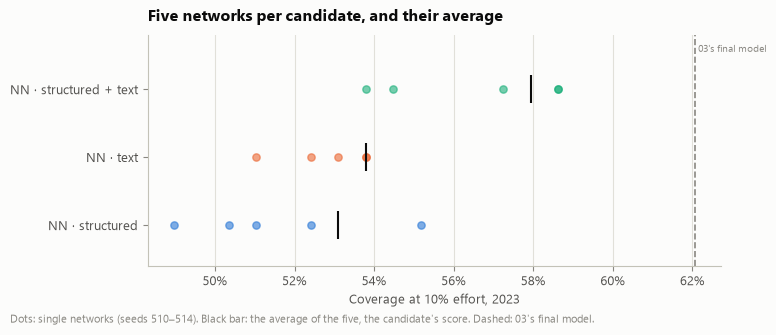

In [27]:
spread = pd.DataFrame({name: {**{f"seed {s}": SEED_COV[(c["feature_set"], c["config"])][k]
                                  for k, s in enumerate(SEEDS)},
                              "average of 5": q5_val.loc[name, primary]}
                       for name, c in CANDIDATES.items()}).T
print(spread.to_string(float_format=lambda v: f"{v:.1%}"))
save_table(spread, "q5_seed_spread")

fig, ax = plt.subplots(figsize=(7.4, 3.0))
for k, (name, c) in enumerate(CANDIDATES.items()):
    seeds = SEED_COV[(c["feature_set"], c["config"])]
    ax.scatter(seeds, np.full(len(seeds), k), color=SET_COLORS[c["feature_set"]], alpha=0.6, s=28, zorder=3)
    ax.scatter([q5_val.loc[name, primary]], [k], color=INK, marker="|", s=400, zorder=4)
ax.axvline(q5_val.loc[f"03 · {FINAL_03}", primary], color=BASELINE_GREY, linestyle="--", linewidth=1.2)
ax.text(q5_val.loc[f"03 · {FINAL_03}", primary], len(CANDIDATES) - 0.45, " 03's final model", fontsize=7.5, color=INK_3)
ax.set_yticks(range(len(CANDIDATES)), list(CANDIDATES))
ax.set_ylim(-0.6, len(CANDIDATES) - 0.2)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.set_xlabel("Coverage at 10% effort, 2023")
ax.set_title("Five networks per candidate, and their average", pad=10)
save_figure(fig, "q5_seed_spread", "Dots: single networks (seeds 510–514). Black bar: the average of the five, the "
            "candidate's score. Dashed: 03's final model.")

**Reading the result:** a table and a chart: five dots per candidate (single networks) and a black bar
(their average). Dots spread over several points mean single networks are noisy; the average usually
sits near or above the middle of its dots.

### Step 16 · The curves on 2023

**What we are doing:** the coverage curves of the final network, the structured-only network and 03's
final model, with 03's function, word for word.

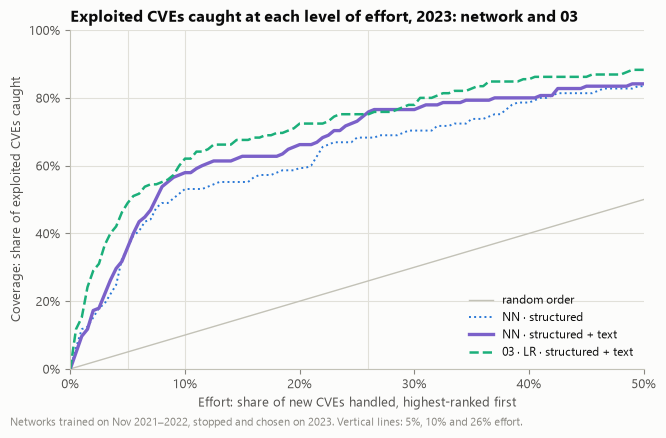

In [28]:
def coverage_curves(y, scores, styles, rules, title, name, note):
    "Coverage against effort (0-50%) for several rankings, with the Q1 rules as points."
    efforts = np.linspace(0, 0.5, 101)
    fig, ax = plt.subplots(figsize=(7.4, 4.4))
    ax.plot([0, 0.5], [0, 0.5], color=AXIS, linewidth=1, label="random order")
    for label, (color, width, dash) in styles.items():
        ax.plot(efforts, coverage(Ranking(scores[label]), y, efforts)[0], color=color, linewidth=width,
                linestyle=dash, label=label)
    beyond = [f"{r.replace('rule: ', '')} ({e:.0%} effort, {c:.0%} coverage)" for r, (e, c) in rules.items() if e > 0.5]
    for rule, (effort, cov) in ((r, ec) for r, ec in rules.items() if ec[0] <= 0.5):
        ax.plot(effort, cov, "o", color=INK, markersize=5, zorder=4)
        ax.annotate(rule.replace("rule: ", ""), (effort, cov), xytext=(6, -12), textcoords="offset points",
                    fontsize=8, color=INK_2)
    for e in EFFORTS:
        ax.axvline(e, color=GRID, linewidth=0.8, zorder=0)
    ax.set_xlim(0, 0.5)
    ax.set_ylim(0, 1.0)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="y")
    ax.set_xlabel("Effort: share of new CVEs handled, highest-ranked first")
    ax.set_ylabel("Coverage: share of exploited CVEs caught")
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8.5)
    save_figure(fig, name, note + (f"\nBeyond the right edge: rule {'; '.join(beyond)}." if beyond else ""))

STYLES = {"NN · structured": (SET_COLORS["structured"], 1.4, ":"), FINAL_NN: (NN_COLOR, 2.4, "-"),
          f"03 · {FINAL_03}": (SET_COLORS["structured + text"], 1.8, "--")}
coverage_curves(y_val, val_scores, STYLES, {}, "Exploited CVEs caught at each level of effort, 2023: network and 03",
                "q5_coverage_validation", "Networks trained on Nov 2021–2022, stopped and chosen on 2023. "
                "Vertical lines: 5%, 10% and 26% effort.")

**Reading the chart:** where the violet curve (the final network) runs above the dashed aqua one (03's
final model), reading meaning beats counting words at that effort; where they cross, it depends on the
team's capacity.

---

## Stage F · The test year

### Step 17 · Freeze every choice before 2024 is touched

**What we are doing:** as in 03 (Step 21), writing every choice down in `results/q5_selection.json` with
a SHA-256 fingerprint: the three candidates (settings and the epoch each seed stopped at), the final
network, the language model and its revision, and the network's settings.

**Why:** the fingerprint proves that 2024 is scored with choices fixed beforehand. The test-year copy
must print the same fingerprint as this copy.

In [29]:
SELECTION = {"final_network": FINAL_NN, "candidates": CANDIDATES,
             "language_model": {"name": MODEL_NAME, "revision": MODEL_REVISION},
             "settings": {"hidden": HIDDEN, "learning_rate": LEARNING_RATE, "batch_size": BATCH_SIZE,
                          "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "grid": NET_GRID, "seeds": SEEDS,
                          "min_category": MIN_CATEGORY, "efforts": EFFORTS, "primary_effort": PRIMARY_EFFORT,
                          "text": "cleaned: sentences stating exploitation removed"},
             "validation_coverage": {n: round(float(v), 6) for n, v in q5_val.loc[list(CANDIDATES), primary].items()}}
SELECTION_SHA = hashlib.sha256(json.dumps(SELECTION, sort_keys=True, default=str).encode("utf-8")).hexdigest()
save_json({"sha256": SELECTION_SHA, "frozen_at": now_iso(), **SELECTION}, RESULTS / "q5_selection.json")
print(f"final network: {FINAL_NN} {CANDIDATES[FINAL_NN]['params']}")
print(f"selection fingerprint: {SELECTION_SHA[:16]}…")
check("G1-selection-frozen", True, sha256=SELECTION_SHA, final_network=FINAL_NN)

final network: NN · structured + text {'dropout': 0.2, 'weight_decay': 0.0001}
selection fingerprint: 9fadc43620319db5…
PASS  G1-selection-frozen  |  {'sha256': '9fadc43620319db5a50095a75968137dba4b9e87fdab54b23d9b482fdf233628', 'final_network': 'NN · structured + text'}


**Reading the result:** the final network and the first 16 characters of the fingerprint. Run on the
same computer, the test-year copy must print the same fingerprint.

### Step 18 · Scoring 2024, once

**What we are doing:** two functions, run only when `EVALUATE_TEST = True`.

- `open_test_year` logs the opening (time and fingerprint) in `logs/test_openings_nn.json`, then loads
  the 2024 rows, cleans their descriptions as before, and encodes them (cached like the others).
- `score_test_year` refits the structured encoder on Nov 2021–2023 and, for each candidate and seed,
  trains a network **on Nov 2021–2023 for exactly the number of epochs that seed stopped at on 2023**,
  then averages the five networks' 2024 scores.

**Why refit on both years, for a fixed number of epochs:** as in 03, a team deploying the network in
2024 would use every labelled CVE it had. Early stopping needs a year to watch; once 2023 is part of the
training data, the number of epochs found on 2023 takes its place, so no 2024 information is used.

In [30]:
OPENINGS = LOGS / "test_openings_nn.json"

def open_test_year():
    "Log this opening, then return the 2024 rows (cleaned), their embeddings, and earlier fingerprints."
    openings = json.loads(OPENINGS.read_text(encoding="utf-8")) if OPENINGS.exists() else []
    earlier = sorted({o["selection_sha256"] for o in openings})
    openings.append({"opened": now_iso(), "selection_sha256": SELECTION_SHA, "final_network": FINAL_NN})
    save_json(openings, OPENINGS)
    test = period_frame("test")
    test["text"] = test["description"].map(mask_exploitation)
    kev_dates = table.set_index("cve_id")["kev_date_added"]                # for the evaluation only, never an input
    test["kev_date_added"] = kev_dates.reindex(test["cve_id"]).to_numpy()
    return test, embeddings("test", test), earlier

def score_test_year(test, test_emb):
    "Refit on Nov 2021-2023 with the frozen settings and epochs; return each candidate's 2024 score (5-seed average)."
    fit_df = pd.concat([frames["train"], frames["validate"]], ignore_index=True)
    y_fit = fit_df[LABEL].to_numpy(int)
    _, parts = network_inputs(fit_df, {"fit": fit_df, "test": test},
                              {"fit": np.vstack([EMB["train"], EMB["validate"]]), "test": test_emb})
    out = {}
    for name, c in CANDIDATES.items():
        X_fit, X_test = matrix(parts["fit"], c["feature_set"]), matrix(parts["test"], c["feature_set"])
        out[name] = np.mean([scores_of(train_net(X_fit, y_fit, c["params"], s, epochs=n)[0], X_test)
                             for s, n in zip(SEEDS, c["epochs"])], axis=0)
        print(f"  {name} refitted and scored")
    return out

**Running it:** the next cell either reports that the test year is sealed, or opens it, scores it, and
measures every ranking on 2024: the three network candidates, 03's final model (its 2024 scores from
`03_model_test.ipynb`), EPSS 1, 7 and 30 days after publication (notebook 01's benchmark, unscored CVEs
last, as in 04), and the severity score.

In [31]:
if not EVALUATE_TEST:
    print("The test year (2024) is sealed: no 2024 label has been read.\n"
          "When the 2023 results above are final, run 05_pytorch_extension_test.ipynb "
          "(the same notebook, test year on).")
else:
    t0 = time.perf_counter()
    test, test_emb, earlier = open_test_year()
    y_test = test[LABEL].to_numpy(int)
    nn_test = score_test_year(test, test_emb)
    scores_03t = pd.read_parquet(PROCESSED / "model_scores_test.parquet")
    epss_long = pd.read_parquet(PROCESSED / "epss_benchmark.parquet")
    epss = pd.DataFrame({"cve_id": test["cve_id"]})
    for h in (1, 7, 30):
        part = epss_long.loc[epss_long["horizon_days"] == h].set_index("cve_id").reindex(test["cve_id"])
        epss[f"epss_{h}"] = part["epss"].to_numpy()
        epss[f"day_{h}"] = part["score_day"].fillna(part["target_day"]).to_numpy()
    aligned = scores_03t["cve_id"].equals(test["cve_id"])
    test_scores = {**nn_test, f"03 · {FINAL_03}": scores_03t[FINAL_03].to_numpy(),
                   **{f"EPSS, day {h}": epss[f"epss_{h}"].fillna(-1.0).to_numpy() for h in (1, 7, 30)},
                   "CVSS score, unscored slotted in": scores_03t["CVSS score, unscored slotted in"].to_numpy()}
    q5_test, boot_test = evaluation_table(y_test, test_scores)
    print(f"2024: {len(test):,} CVEs, {int(y_test.sum())} exploited | scored in {time.perf_counter() - t0:.0f} s\n")
    print(q5_test[cols + ["average_precision"]].to_string(float_format=lambda v: f"{v:.1%}"))
    save_table(q5_test, "q5_test_results")
    pd.DataFrame({"cve_id": test["cve_id"], **nn_test}).to_parquet(PROCESSED / "nn_scores_test.parquet", index=False)
    RUN["files"].append(str(PROCESSED / "nn_scores_test.parquet"))
    reopened = [sha for sha in earlier if sha != SELECTION_SHA]
    check("G2-test-evaluated", False if not aligned else (None if reopened else True), cves=len(test),
          exploited=int(y_test.sum()), scores_03_aligned=aligned, other_selections_before=len(reopened))

The test year (2024) is sealed: no 2024 label has been read.
When the 2023 results above are final, run 05_pytorch_extension_test.ipynb (the same notebook, test year on).


**Reading the result:** (only when the test year is opened) the 2024 table: coverage at three efforts
with intervals, and average precision, for every ranking. `G2` is `PASS` when 03's 2024 scores line up
with the CVEs and no earlier opening used other choices.

### Step 19 · The differences on 2024, and the fair comparison with EPSS

**What we are doing:** with the test year open, the paired differences at every effort: the final
network minus 03's final model; the network with text minus the structured-only network; and the final
network minus EPSS on each day. Then, as in 04, the comparison with EPSS **on equal information**: for
each EPSS day, without the exploited CVEs KEV had already listed by the day that score describes (EPSS
reads KEV). Finally the 2024 curves.

In [32]:
if EVALUATE_TEST:
    pairs = [(f"03 · {FINAL_03}", FINAL_NN), ("NN · structured", "NN · structured + text")]
    pairs += [(f"EPSS, day {h}", FINAL_NN) for h in (1, 7, 30)]
    q5_test_diff = difference_table(q5_test, boot_test, pairs)
    print(q5_test_diff.to_string(index=False, formatters=FMT))
    save_table(q5_test_diff, "q5_test_differences", index=False)

    rows = []
    for h in (1, 7, 30):
        listed = test["kev_date_added"].notna() & (test["kev_date_added"] <= pd.to_datetime(epss[f"day_{h}"]))
        keep = ~(listed.to_numpy() & (y_test == 1))
        t_h, b_h = evaluation_table(y_test[keep], {FINAL_NN: test_scores[FINAL_NN][keep],
                                                   f"EPSS, day {h}": test_scores[f"EPSS, day {h}"][keep]})
        for e in EFFORTS:
            change, low, high = difference(t_h, b_h, f"EPSS, day {h}", FINAL_NN, e)
            rows.append({"epss_day": h, "exploited_kept": int(y_test[keep].sum()), "effort": e,
                         "network": t_h.loc[FINAL_NN, f"coverage_{tag(e)}"],
                         "epss": t_h.loc[f"EPSS, day {h}", f"coverage_{tag(e)}"],
                         "change": change, "low": low, "high": high, "clear": bool(low > 0 or high < 0)})
    q5_fair = pd.DataFrame(rows)
    print("\nthe final network against EPSS on equal information:")
    print(q5_fair.to_string(index=False, formatters={**FMT, "network": "{:.1%}".format, "epss": "{:.1%}".format}))
    save_table(q5_fair, "q5_test_equal_information", index=False)
    coverage_curves(y_test, test_scores, {**STYLES, "EPSS, day 30": ("#5b43a8", 1.4, "-.")}, {},
                    "Exploited CVEs caught at each level of effort, 2024 (test): the network, 03 and EPSS",
                    "q5_coverage_test", "Networks refitted on Nov 2021–2023 with the frozen settings and epochs, "
                    "measured once on 2024. EPSS day 30: scored a month after publication.")
else:
    print("sealed: nothing to compare yet")

sealed: nothing to compare yet


**Reading the result:** each row is a ranking minus another, in points, with its 95% interval; then the
final network against EPSS without the already-listed exploited CVEs; then the 2024 curves.

---

## Stage G · Summary

### Step 20 · Key findings, checks and files

**What we are doing:** collecting the headline numbers in `results/q5_summary.json`
(`q5_summary_test.json` in the test-year copy), then listing every check and file and saving the run log.

In [33]:
def at(table_, name, effort):
    "Coverage of one ranking at one effort, with its interval, as text."
    est, low, high = (table_.loc[name, f"coverage_{tag(effort)}{s}"] for s in ("", "_low", "_high"))
    return f"{est:.1%} ({low:.1%}–{high:.1%})"

def change_text(row):
    return f"{row['change']:+.1%} ({row['low']:+.1%} to {row['high']:+.1%}){'' if row['clear'] else ', not clear'}"

d10 = q5_val_diff[np.isclose(q5_val_diff["effort"], PRIMARY_EFFORT)].set_index(["ranking", "minus"])
FINDINGS = {
    "final network": f"{FINAL_NN}, settings {CANDIDATES[FINAL_NN]['params']}, "
                     f"epochs per seed {CANDIDATES[FINAL_NN]['epochs']}",
    "language model": f"{MODEL_TAG}, {dim} numbers per description",
    "2023 coverage, final network": "; ".join(f"{e:.0%} effort: {at(q5_val, FINAL_NN, e)}" for e in EFFORTS),
    "2023 coverage, 03's final model": "; ".join(f"{e:.0%} effort: {at(q5_val, f'03 · {FINAL_03}', e)}"
                                                 for e in EFFORTS),
    "2023, network minus 03 at 10%": change_text(d10.loc[(FINAL_NN, f"03 · {FINAL_03}")]),
    "2023, meaning added to the structured fields at 10%":
        change_text(d10.loc[("NN · structured + text", "NN · structured")]),
}
if EVALUATE_TEST:
    t10 = q5_test_diff[np.isclose(q5_test_diff["effort"], PRIMARY_EFFORT)].set_index(["ranking", "minus"])
    f10 = q5_fair[np.isclose(q5_fair["effort"], PRIMARY_EFFORT)].set_index("epss_day")
    FINDINGS["2024 coverage, final network"] = "; ".join(f"{e:.0%} effort: {at(q5_test, FINAL_NN, e)}" for e in EFFORTS)
    FINDINGS["2024, network minus 03 at 10%"] = change_text(t10.loc[(FINAL_NN, f"03 · {FINAL_03}")])
    FINDINGS["2024, network minus EPSS at 10%, all CVEs"] = "; ".join(
        f"day {h}: {change_text(t10.loc[(FINAL_NN, f'EPSS, day {h}')])}" for h in (1, 7, 30))
    FINDINGS["2024, network minus EPSS at 10%, equal information"] = "; ".join(
        f"day {h}: {change_text(f10.loc[h])}" for h in (1, 7, 30))
for topic, text in FINDINGS.items():
    print(f"- {topic}: {text}")
save_json(FINDINGS, SUMMARY_FILE)

- final network: NN · structured + text, settings {'dropout': 0.2, 'weight_decay': 0.0001}, epochs per seed [1, 2, 1, 2, 2]
- language model: sentence-transformers/all-MiniLM-L6-v2@1110a243fdf4706b3f48f1d95db1a4f5529b4d41, 384 numbers per description
- 2023 coverage, final network: 5% effort: 35.9% (27.8%–43.5%); 10% effort: 57.9% (49.6%–65.8%); 26% effort: 75.9% (68.3%–82.3%)
- 2023 coverage, 03's final model: 5% effort: 49.0% (40.0%–56.7%); 10% effort: 62.1% (53.5%–69.7%); 26% effort: 75.2% (67.8%–82.1%)
- 2023, network minus 03 at 10%: -4.1% (-10.6% to +2.3%), not clear
- 2023, meaning added to the structured fields at 10%: +4.8% (+0.0% to +9.9%), not clear


**Reading the result:** one line per headline finding, with 95% intervals in brackets.

**The checks and files:** the last cell lists every check and file and saves the run log.

In [34]:
EXPECTED_CHECKS = ["A1-evaluation-selftest", "B1-table-loaded", "B2-inputs-permitted", "C1-description-masking",
                   "D0-cvss-parser-selftest", "C2-embeddings", "D1-network-selftest", "E1-networks-trained",
                   "G1-selection-frozen"]
EXPECTED_CHECKS += ["G2-test-evaluated"] if EVALUATE_TEST else []
for name in EXPECTED_CHECKS:
    RUN["checks"].setdefault(name, {"verdict": "FAIL", "error": "check never ran"})
RUN["finished"] = now_iso()
LOG_FILE.write_text(json.dumps(RUN, indent=2, default=str), encoding="utf-8")

verdicts = [c["verdict"] for c in RUN["checks"].values()]
print(f"{verdicts.count('PASS')}/{len(verdicts)} checks passed, {verdicts.count('WARN')} to review, "
      f"{verdicts.count('FAIL')} failed | test year {'opened' if EVALUATE_TEST else 'sealed'}")
for name, c in RUN["checks"].items():
    print(f"  {c['verdict']:<5} {name}")
print(f"\n{len(RUN['files'])} files written:")
for path in RUN["files"]:
    print(f"  {path}")

9/9 checks passed, 0 to review, 0 failed | test year sealed
  PASS  A1-evaluation-selftest
  PASS  B1-table-loaded
  PASS  B2-inputs-permitted
  PASS  C1-description-masking
  PASS  D0-cvss-parser-selftest
  PASS  C2-embeddings
  PASS  D1-network-selftest
  PASS  E1-networks-trained
  PASS  G1-selection-frozen

11 files written:
  data\processed\embeddings\train.npz
  data\processed\embeddings\validate.npz
  results\q5_validation_grid.csv
  results\q5_validation_models.csv
  data\processed\nn_scores_validate.parquet
  results\q5_validation_differences.csv
  results\q5_seed_spread.csv
  figures\q5_seed_spread.png
  figures\q5_coverage_validation.png
  results\q5_selection.json
  results\q5_summary.json


**Reading the result:** the target is 9 of 9 checks passed with the test year sealed (10 of 10 once
opened).

## What comes next

1. **Review the 2023 results** (Stage E): does reading meaning beat 03's word counts, and by how much?
2. **Open the test year once:** run `05_pytorch_extension_test.ipynb` on the same computer. Its
   fingerprint in Step 17 must equal this copy's.
3. **The report:** the extension's findings come from `results/q5_summary.json` and
   `q5_summary_test.json`.